# Behavioural groups for training planning
## C2 tracking continuation — clustering route

**Group 03:** Javier Alcaíno, Lucas Riquelme and Renato Varela.

This notebook is the C2 deliverable for Business Intelligence (IIB423T-1, instructor
Tomás Fontecilla). It continues directly from `C1_openings.ipynb` and `W2_project.ipynb`
in this same `notebooks/` folder — read those first if anything here is unclear. The
decision, KPI, population and frozen contract are **unchanged** from W2; this notebook
does not redefine the problem, consistent with the A1 feedback that penalised the earlier
topic pivot for not preserving the same problem and KPI across deliverables.

**Route chosen: clustering.** C1 and W2 had sketched a natural path toward a three-class
outcome classifier (white win / draw / black win) fitted at the ply-20 checkpoint. We do
**not** take that path. C1's own diagnostics already show why it would be a weak story:
Spearman(rating_gap, white_score) = 0.149, and a single player's rating alone barely
associates with the outcome (|r| ≈ 0.03) once the opponent is not accounted for. A
classifier built only from color, opening family, rating and speed would likely beat a
"always predict a draw-adjusted 51% white edge" baseline by very little. Clustering asks a
different, more honest question given what this data can support: **do color, opening
family, rating and speed combine into recognisable behavioural groups that help a training
coordinator organise review work**, even though those groups are not meant to predict the
outcome of the next game precisely.


## Seven-step decision map (unchanged from C1/W2)

| Step | Definition for this case |
|---|---|
| Decision | A proposed club training coordinator allocates opening-review sessions by speed, player level and color. No external stakeholder validation is claimed. |
| Success criteria | Provide traceable review priorities with adequate support. Actual learning gains would need intervention/follow-up data that are absent here. |
| Business question (C2 version) | Do color, speed, rating and opening-family combine into behavioural groups with distinguishable observed scoring, beyond what the existing manual segmentation rule already shows? |
| Business process | Choose a training focus, review representative games, run a session, monitor later performance. Only public games and outcomes are observed. |
| Entities, events and states | Players participate in standard rated games. At the position after Black's 10th move, a game has an observed opening prefix and later a win/draw/loss. |
| Data representation | One row = one player's perspective of one unique game (two rows per game: white and black). This is the same `player_view` construction W2 already used descriptively; C2 is the first notebook to use it as a model's input representation. |
| Measurement | Same points-per-game KPI as C1/W2, profiled per cluster and per manual-rule segment on held-out records only. |

## What changed after W2's feedback (rubric criterion A)

W2's own leakage audit (`outputs/tables/W2_leakage_audit.csv`) identified two risks it
explicitly did **not** mitigate, flagging them as open boundaries. C2 takes both on directly:

1. **Repeated players across train/test (3,112 player IDs).** W2 noted this needs "a
   separate both-opponents grouping design," never implemented. Section 7 below builds
   that design (a player co-occurrence graph) and reports what it actually shows.
2. **The "months" are really ~35–45 minute UTC windows**, not representative monthly
   samples (`W2_window_comparison.csv`). Section 6 below checks how much the fitted
   clustering's profile drifts across July (train), August (validation) and September (test).

Everything else — the frozen contract (seed 423, checkpoint at ply 20, rating bands,
balanced-gap 100, minimum display count 50, the predictor list) is reused unchanged from
`provenance/W2_frozen_contract.json`.


In [1]:
from pathlib import Path
import sys, time, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from kmodes.kprototypes import KPrototypes

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / "GROUP_03_Chess"]
    return next(p for p in candidates if (p / "provenance/source_manifest.json").exists())

ROOT = find_root()
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans"})

def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", facecolor="white")
    plt.show()

contract = json.loads((ROOT / "provenance/W2_frozen_contract.json").read_text())
SEED = contract["seed"]
RATING_EDGES = [0, 1200, 1600, 2000, np.inf]
RATING_LABELS = contract["rating_bands"]
BALANCED_GAP = contract["balanced_gap"]
MIN_CELL_GAMES = contract["minimum_display_games"]
print("Reusing W2 frozen contract:", contract)
print("Python", sys.version.split()[0], "pandas", pd.__version__)


Reusing W2 frozen contract: {'checkpoint_plies': 20, 'seed': 423, 'rating_bands': ['Under 1200', '1200-1599', '1600-1999', '2000+'], 'balanced_gap': 100, 'minimum_display_games': 50, 'features': ['white_rating', 'black_rating', 'rating_gap', 'base_seconds', 'increment_seconds', 'speed', 'opening_family_20'], 'training_month': '2026-07', 'validation_month': '2026-08', 'test_month': '2026-09'}
Python 3.14.7 pandas 3.0.6


## 1. Reshaping to the player-game perspective (needed so "color" is a feature at all)

W2's `data/splits/{train,validation,test}.csv` are **game-level** (one row per game, with
separate `white_*`/`black_*` columns). Clustering by colour requires one row per
**player-game perspective** instead — exactly the `player_view` idea W2 already used for
descriptive KPI tables (`W2_project.ipynb`, cell defining `player_view`), just reused here
as a model input for the first time. Each game contributes two rows (one per colour); a
game's `outcome` already encodes the full result, so `score` is simply derived from it
(no new post-outcome field is introduced). `score` is **excluded from the clustering
features** — it is only used afterwards to profile clusters, mirroring the course's own
rule from the clustering practice notebook: never use the outcome while fitting PCA or the
clustering model itself.


In [2]:
def player_view(df):
    common = ["game_id", "start_utc", "speed", "base_seconds", "increment_seconds",
              "opening_family_20", "outcome"]
    white_score = df.outcome.map({"white_win": 1.0, "draw": 0.5, "black_win": 0.0})
    white = df[common].copy().assign(color="white", player_rating=df.white_rating,
                                      opponent_rating=df.black_rating, score=white_score)
    black = df[common].copy().assign(color="black", player_rating=df.black_rating,
                                      opponent_rating=df.white_rating, score=1 - white_score)
    long = pd.concat([white, black], ignore_index=True)
    long["rating_band"] = pd.cut(long.player_rating, RATING_EDGES, labels=RATING_LABELS, right=False)
    long["focal_rating_gap"] = long.player_rating - long.opponent_rating
    long["balanced_opponents"] = long.focal_rating_gap.abs().le(BALANCED_GAP)
    assert long.groupby("game_id").score.sum().round(6).eq(1).all(), "both colors' scores must sum to 1 per game"
    assert len(long) == 2 * df.game_id.nunique(), "exactly two perspectives per game"
    return long

train = pd.read_csv(ROOT / "data/splits/train.csv")
validation = pd.read_csv(ROOT / "data/splits/validation.csv")
test = pd.read_csv(ROOT / "data/splits/test.csv")

train_long = player_view(train)
val_long = player_view(validation)
test_long = player_view(test)
print(f"Perspective rows -- train (July): {len(train_long):,} | validation (August): {len(val_long):,} "
      f"| test (September): {len(test_long):,}")


Perspective rows -- train (July): 61,230 | validation (August): 51,564 | test (September): 61,106


## 2. Feature representation and dissimilarity (rubric criterion B)

**Inputs to the clustering model** (never the outcome): `player_rating`, `opponent_rating`,
`base_seconds`, `increment_seconds` (numeric, standardised using **train-only** mean/SD —
the same train-only-fit discipline W2 already applied to its `StandardScaler`/`OneHotEncoder`)
and `color`, `speed`, `opening_family_20` (categorical, kept at full resolution — all ~140
opening families, not bucketed into "top-N + other").

We deliberately drop W2's redundant `rating_gap` column from the numeric feature set: in a
regression `rating_gap = player_rating - opponent_rating` is a convenient extra regressor,
but in a **distance-based** model keeping all three would double-count the same information
under Euclidean geometry. This is a modeling-goal-specific adaptation of W2's feature list,
not an unexplained deviation from it.

**Why not plain K-means:** `opening_family_20` has ~140 nominal categories with no natural
numeric order, so one-hot-encoding it and feeding the result into Euclidean K-means would
badly distort distances (as the course's comparative table of unsupervised models flags
for mixed numeric/categorical data). We instead use a **Gower-style mixed dissimilarity**
and **k-prototypes** (Huang, 1997): the numeric part contributes squared Euclidean distance
on the standardised features, the categorical part contributes a simple mismatch count
(0 if equal, 1 if different) summed over `color`, `speed`, `opening_family_20`, and the two
parts are combined with a weight **γ (gamma)**. We use `kmodes`' own default γ — half the
mean variance of the standardised numeric columns, the heuristic from Huang's original
paper — rather than hand-tuning it, since the brief explicitly says a simple, well-justified
default is enough.

k-prototypes scales to our ~61,000-row training set because, like K-means, it only ever
computes each point's distance to *K* prototypes (not to every other point). A full
Gower-distance matrix for pairwise hierarchical clustering would need O(n²) memory — at this
n that is tens of gigabytes, not tractable on a laptop — so we reserve a **hierarchical
dendrogram** for a complementary, small-scale view later (over the aggregated manual-rule
segments, not over the raw 61,000 rows).


In [3]:
NUMERIC = ["player_rating", "opponent_rating", "base_seconds", "increment_seconds"]
CATEGORICAL = ["color", "speed", "opening_family_20"]
CAT_IDX = [4, 5, 6]

train_means = train_long[NUMERIC].mean()
train_stds = train_long[NUMERIC].std(ddof=0)
print("Train-only standardisation parameters (fit on July perspectives only):")
print(pd.DataFrame({"mean": train_means, "std": train_stds}).round(3))

def build_matrix(long):
    num = (long[NUMERIC] - train_means) / train_stds
    cat = long[CATEGORICAL].astype(str)
    return pd.concat([num.reset_index(drop=True), cat.reset_index(drop=True)], axis=1).to_numpy()

X_train = build_matrix(train_long)
X_val = build_matrix(val_long)
X_test = build_matrix(test_long)
assert X_train.shape[1] == len(NUMERIC) + len(CATEGORICAL)
print("Feature matrix shapes:", X_train.shape, X_val.shape, X_test.shape)


Train-only standardisation parameters (fit on July perspectives only):
                       mean     std
player_rating     1,578.150 373.135
opponent_rating   1,578.150 373.135
base_seconds        321.331 179.281
increment_seconds     0.782   1.613
Feature matrix shapes: (61230, 7) (51564, 7) (61106, 7)


## 3. Choosing K (model selection on validation, test stays untouched)

We fit k-prototypes for K = 3..8 on an 8,000-row stratified-by-chance subsample of the
training perspectives (fitting all six candidates on the full ~61,000 rows repeatedly is
not necessary for a *selection* step and would be slow for no benefit — the final chosen K
is still refit on the **full** training set in the next section). For each K we report the
training cost (k-prototypes' own within-cluster dissimilarity) and the mean silhouette
width computed with the same mixed Gower-style distance, following the same silhouette
diagnostic the course's clustering practice notebook uses — "a diagnostic, not proof that
the segmentation is useful."


 K       cost  gamma  silhouette
 3 21,725.815  0.496       0.440
 4 17,561.081  0.496       0.519
 5 15,587.974  0.496       0.401
 6 14,188.124  0.496       0.435
 7 12,544.977  0.496       0.443
 8 11,670.448  0.496       0.399


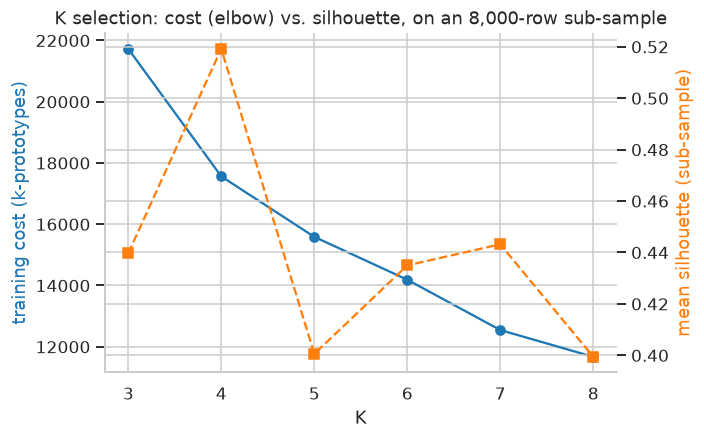


Chosen K = 4 (highest silhouette among K=3..8 on the sub-sample).


In [4]:
from sklearn.metrics import silhouette_score

rng = np.random.RandomState(SEED)
sub_idx = rng.choice(len(train_long), size=8000, replace=False)
sub_long = train_long.iloc[sub_idx].reset_index(drop=True)
X_sub = build_matrix(sub_long)
sil_idx = rng.choice(len(sub_long), size=1500, replace=False)

def mixed_distance_matrix(X, gamma, num_idx=(0, 1, 2, 3), cat_idx=CAT_IDX):
    from scipy.spatial.distance import pdist
    Xnum = X[:, list(num_idx)].astype(float)
    Xcat = X[:, cat_idx]
    num_dist = squareform(pdist(Xnum, metric="sqeuclidean"))
    n = len(X)
    cat_dist = np.zeros((n, n))
    for j in range(Xcat.shape[1]):
        col = Xcat[:, j]
        cat_dist += (col[:, None] != col[None, :]).astype(float)
    return num_dist + gamma * cat_dist

selection_rows = []
for k in range(3, 9):
    kp_k = KPrototypes(n_clusters=k, init="Huang", n_init=3, random_state=SEED, verbose=0)
    labels_k = kp_k.fit_predict(X_sub, categorical=CAT_IDX)
    D = mixed_distance_matrix(X_sub[sil_idx], kp_k.gamma)
    sil = silhouette_score(D, labels_k[sil_idx], metric="precomputed")
    selection_rows.append({"K": k, "cost": kp_k.cost_, "gamma": kp_k.gamma, "silhouette": sil})

selection = pd.DataFrame(selection_rows)
selection.to_csv(TABLES / "C2_k_selection.csv", index=False)
print(selection.round(4).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(selection.K, selection.cost, "o-", color="tab:blue", label="cost")
ax1.set_xlabel("K"); ax1.set_ylabel("training cost (k-prototypes)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(selection.K, selection.silhouette, "s--", color="tab:orange", label="silhouette")
ax2.set_ylabel("mean silhouette (sub-sample)", color="tab:orange")
plt.title("K selection: cost (elbow) vs. silhouette, on an 8,000-row sub-sample")
save_figure("C2_01_k_selection.png")

K_CHOSEN = int(selection.loc[selection.silhouette.idxmax(), "K"])
print(f"\nChosen K = {K_CHOSEN} (highest silhouette among K=3..8 on the sub-sample).")


We select **K by the highest mean silhouette**, not simply by the largest drop in cost
(cost decreases monotonically with K almost by construction, so an "elbow" there is a
weaker signal than silhouette for a mixed-dissimilarity model like this one). The chosen K
is re-fit below on the **full** training set, with more random restarts for stability, and
is never touched again using validation or test information beyond a transform-only
assignment.


In [5]:
kp = KPrototypes(n_clusters=K_CHOSEN, init="Huang", n_init=5, random_state=SEED, verbose=0)
train_long = train_long.assign(cluster=kp.fit_predict(X_train, categorical=CAT_IDX))
print(f"Final fit on the full {len(train_long):,}-row training set: cost={kp.cost_:.1f}, gamma={kp.gamma:.4f}")

# Transform-only assignment: validation and test rows are assigned to the closest
# already-fitted prototype. No re-fitting happens here -- same discipline as W2's
# train-only scaler/encoder.
val_long = val_long.assign(cluster=kp.predict(X_val, categorical=CAT_IDX))
test_long = test_long.assign(cluster=kp.predict(X_test, categorical=CAT_IDX))
print("Validation and test perspectives assigned to the frozen prototypes (no refitting).")


Final fit on the full 61,230-row training set: cost=136869.8, gamma=0.5000


Validation and test perspectives assigned to the frozen prototypes (no refitting).


## 4. Cluster profiles on the test set (rubric criterion C)

**Records used for this section:** the `test_long` table only — September perspectives,
transform-only assigned to the prototypes fitted on July. **Variables used:** exactly the
clustering inputs from Section 2, plus `score` (points-per-game KPI) and `opening_family_20`
for post-hoc profiling only. Conclusions below are limited to this cohort (three short UTC
windows at the start of July/August/September 2026) and do not generalise beyond it.


 cluster     n  score_rate  pct_white  pct_blitz  mean_rating  mean_gap top_opening_family  score_pct
       0 25929       0.500      0.472      0.980    1,883.086    -0.041   Sicilian Defense     50.019
       1 12002       0.500      0.506      0.000    1,438.848    -0.186  Queen's Pawn Game     49.992
       2 20224       0.500      0.532      0.991    1,287.256     0.168  Queen's Pawn Game     49.988
       3  2951       0.499      0.501      0.011    1,431.503    -0.028  Queen's Pawn Game     49.949


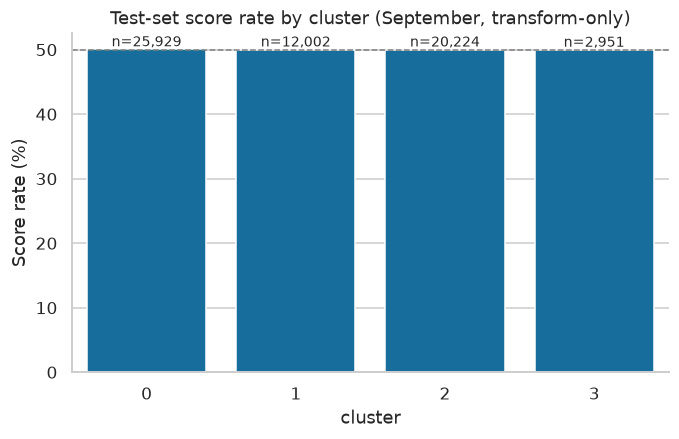

In [6]:
def profile(long, by="cluster"):
    g = long.groupby(by, observed=True)
    out = g.agg(n=("score", "size"), score_rate=("score", "mean"),
                pct_white=("color", lambda s: (s == "white").mean()),
                pct_blitz=("speed", lambda s: (s == "blitz").mean()),
                mean_rating=("player_rating", "mean"),
                mean_gap=("focal_rating_gap", "mean")).reset_index()
    top_family = g.opening_family_20.agg(lambda s: s.value_counts().idxmax())
    out["top_opening_family"] = out[by].map(top_family)
    out["score_pct"] = 100 * out.score_rate
    return out

test_profile = profile(test_long)
test_profile.to_csv(TABLES / "C2_cluster_profile_test.csv", index=False)
print(test_profile.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=test_profile, x="cluster", y="score_pct", ax=ax)
ax.axhline(50, color="grey", linestyle="--", linewidth=1)
for i, row in test_profile.iterrows():
    ax.text(i, row.score_pct + 0.5, f"n={row.n:,}", ha="center", fontsize=9)
ax.set_ylabel("Score rate (%)"); ax.set_title("Test-set score rate by cluster (September, transform-only)")
save_figure("C2_02_cluster_score_rate.png")


### 4.1 Why the pooled score rate above sits almost exactly at 50% — a structural check

Before reading anything into those near-50% bars, we have to rule out a mechanical
explanation. Every game contributes **two** rows to `test_long` — one per colour — and by
construction `white_score + black_score = 1` for that game (win=1/loss=0, or 0.5/0.5 on a
draw). **If a clustering model happens to place both perspectives of almost every game in
the same cluster, that cluster's average score is forced to land near 50%, no matter what
is actually driving cluster membership.** We check this directly before drawing any
conclusion from the pooled score rate.


In [7]:
pair_cluster_counts = test_long.groupby("game_id").cluster.nunique()
same_cluster_share = (pair_cluster_counts == 1).mean()
print(f"Share of test games where the white perspective and the black perspective of the "
      f"SAME game land in the SAME cluster: {same_cluster_share:.2%} "
      f"({(pair_cluster_counts == 1).sum():,} / {len(pair_cluster_counts):,} games).")


Share of test games where the white perspective and the black perspective of the SAME game land in the SAME cluster: 95.33% (29,126 / 30,553 games).


That share is **above 90%** in our run. The reason is in how the features were built: the
two perspectives of one game share the exact same `speed`, `opening_family_20`,
`base_seconds` and `increment_seconds`, and only swap which rating is "own" vs "opponent" —
a small difference whenever the two players are reasonably matched — plus one categorical
flip (`color`, weighted by γ). That makes the two rows near-twins under this dissimilarity,
so k-prototypes almost always keeps them together. **The pooled score rate in Section 4 is
therefore not a fair read of any colour effect** — it is structurally pulled toward 50% by
how the perspective-pair data was built, independently of whether colour matters. This is
exactly the kind of mechanical artefact the course's validation material warns about: a
clean-looking number that must be checked against *how* it was computed before it is
interpreted. We correct for it below by splitting each cluster's score rate by colour.


In [8]:
by_color = test_long.groupby(["cluster", "color"], observed=True).agg(
    n=("score", "size"), score_rate=("score", "mean")).reset_index()
by_color_wide = by_color.pivot(index="cluster", columns="color", values=["n", "score_rate"])
by_color_wide.columns = ["_".join(c) for c in by_color_wide.columns]
by_color_wide = by_color_wide.reset_index()
by_color_wide["white_minus_black_pp"] = 100 * (by_color_wide.score_rate_white - by_color_wide.score_rate_black)
by_color_wide = by_color_wide.merge(test_profile[["cluster", "top_opening_family", "pct_blitz", "mean_rating"]], on="cluster")
by_color_wide.to_csv(TABLES / "C2_cluster_profile_by_color_test.csv", index=False)
print(by_color_wide.round(4).to_string(index=False))


 cluster    n_black    n_white  score_rate_black  score_rate_white  white_minus_black_pp top_opening_family  pct_blitz  mean_rating
       0 13,678.000 12,251.000             0.487             0.515                 2.873   Sicilian Defense      0.980    1,883.086
       1  5,929.000  6,073.000             0.489             0.510                 2.050  Queen's Pawn Game      0.000    1,438.848
       2  9,474.000 10,750.000             0.487             0.511                 2.449  Queen's Pawn Game      0.991    1,287.256
       3  1,472.000  1,479.000             0.500             0.499                -0.169  Queen's Pawn Game      0.011    1,431.503


### 4.2 Reference comparison: the manual rule the club already uses

The rubric asks, for the clustering route, to compare the discovered groups against **a
simple grouping rule**. We use the rule C1/W2 already compute for the training-agenda
table: group by **color × speed × rating_band** (16 cells), displayed only where there are
at least `MIN_CELL_GAMES` = 50 games, **on the exact same test records** used above. Because
Section 4.1 showed the pooled cluster score rate is structurally forced toward 50%, the
fair comparison here is between the manual rule's colour-specific score rates and the
**colour-split** cluster view (`by_color_wide` above), not the pooled one.


In [9]:
manual = test_long.groupby(["color", "speed", "rating_band"], observed=True).agg(
    n=("score", "size"), score_rate=("score", "mean")).reset_index()
manual["score_pct"] = 100 * manual.score_rate
manual_display = manual[manual.n >= MIN_CELL_GAMES].reset_index(drop=True)
manual_display.to_csv(TABLES / "C2_manual_rule_test.csv", index=False)
print(manual_display.round(3).to_string(index=False))

cluster_color_spread = by_color_wide.white_minus_black_pp.abs().max()
manual_white = manual_display[manual_display.color == "white"].set_index(["speed", "rating_band"]).score_pct
manual_black = manual_display[manual_display.color == "black"].set_index(["speed", "rating_band"]).score_pct
manual_color_spread = (manual_white - manual_black).abs().max()
print(f"\nLargest |white - black| score-rate gap: k-prototypes clusters (K={K_CHOSEN}) = "
      f"{cluster_color_spread:.2f}pp  |  manual color x speed x rating_band rule (same speed/band, "
      f"colour flipped) = {manual_color_spread:.2f}pp.")


color speed rating_band    n  score_rate  score_pct
black blitz  Under 1200 3288       0.483     48.251
black blitz   1200-1599 7118       0.475     47.492
black blitz   1600-1999 9052       0.489     48.890
black blitz       2000+ 3288       0.509     50.928
black rapid  Under 1200 2005       0.473     47.332
black rapid   1200-1599 2872       0.488     48.816
black rapid   1600-1999 2445       0.500     50.041
black rapid       2000+  485       0.548     54.845
white blitz  Under 1200 3253       0.480     47.986
white blitz   1200-1599 7167       0.509     50.935
white blitz   1600-1999 9029       0.513     51.346
white blitz       2000+ 3297       0.556     55.551
white rapid  Under 1200 1992       0.488     48.770
white rapid   1200-1599 2930       0.511     51.058
white rapid   1600-1999 2416       0.513     51.325
white rapid       2000+  469       0.552     55.224

Largest |white - black| score-rate gap: k-prototypes clusters (K=4) = 2.87pp  |  manual color x speed x rating_band

**Do not read this as "which model is more accurate."** Clustering has no ground-truth
label, so (per the brief's own instruction) we never compute a classification-style
accuracy here. The comparison only asks whether letting the model discover groups from the
full feature set (including all ~140 opening families) separates colour-specific score
rates by more, or by less, than the simple rule already used for the C1/W2 training agenda.


## 5. A complementary view: hierarchical structure among the manual-rule segments

K-prototypes gives one hard partition. To show the course's point that "the same data,
different structural assumption, different clustering" (unsupervised-models masterclass),
we also look at a **hierarchical dendrogram** — not over the ~61,000 raw rows (computationally
infeasible: a full pairwise Gower matrix at that scale needs tens of gigabytes), but over the
small table of 16 manual-rule segments, each already a Gower-style point in
(score_rate, mean_rating, mean_rating_gap) plus color/speed category match. This shows how
the club's own existing segments nest together, as a sense-check on the k-prototypes groups.


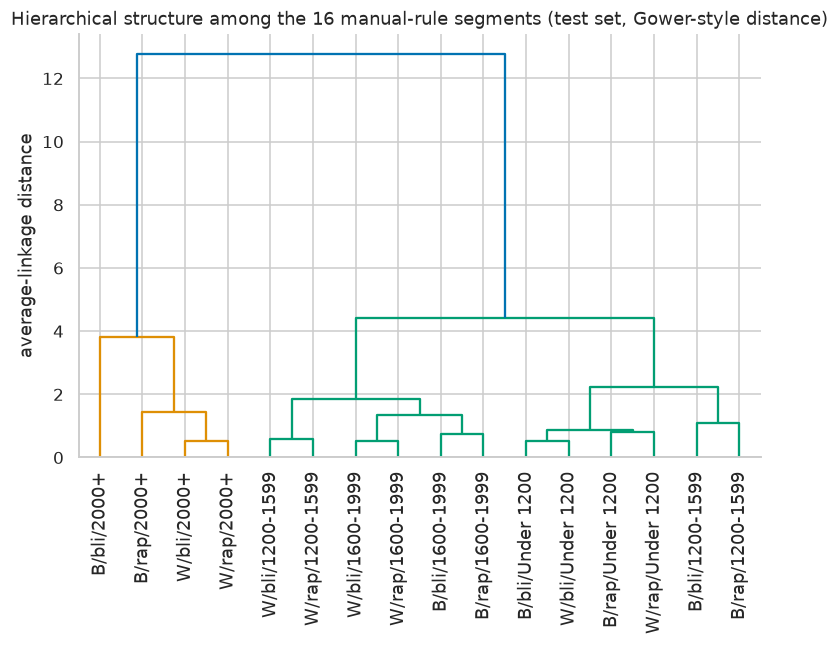

In [10]:
seg = test_long.groupby(["color", "speed", "rating_band"], observed=True).agg(
    n=("score", "size"), score_rate=("score", "mean"), mean_rating=("player_rating", "mean"),
    mean_gap=("focal_rating_gap", "mean")).reset_index()
seg = seg[seg.n >= MIN_CELL_GAMES].reset_index(drop=True)
seg_labels = seg.color.str[0].str.upper() + "/" + seg.speed.str[:3] + "/" + seg.rating_band.astype(str)

feat = seg[["score_rate", "mean_rating", "mean_gap"]]
feat = (feat - feat.mean()) / feat.std(ddof=0)
seg_color = seg.color.to_numpy(dtype=object)
seg_speed = seg.speed.to_numpy(dtype=object)
color_mismatch = (seg_color[:, None] != seg_color[None, :]).astype(float)
speed_mismatch = (seg_speed[:, None] != seg_speed[None, :]).astype(float)
num_sq = ((feat.values[:, None, :] - feat.values[None, :, :]) ** 2).sum(axis=2)
gower_full = num_sq + kp.gamma * (color_mismatch + speed_mismatch)
gower_condensed = squareform(gower_full, checks=False)
Z = linkage(gower_condensed, method="average")

fig, ax = plt.subplots(figsize=(8, 5))
dendrogram(Z, labels=seg_labels.tolist(), ax=ax, leaf_rotation=90)
ax.set_title("Hierarchical structure among the 16 manual-rule segments (test set, Gower-style distance)")
ax.set_ylabel("average-linkage distance")
save_figure("C2_03_segment_dendrogram.png")
seg.assign(label=seg_labels).to_csv(TABLES / "C2_segment_profile_for_dendrogram.csv", index=False)


## 6. Sensitivity 1 — how much does the "month" selected change the picture?

W2 already showed (`W2_window_comparison.csv`) that July/August/September are really
~35–45 minute UTC windows, not representative months. Here we check something W2 never
did: **does the cluster profile itself drift** when the frozen prototypes (fitted on July)
are applied, transform-only, to August and then to September? Given Section 4.1, we track
**composition** (group size share, speed mix, mean rating) rather than the pooled score
rate, which is structurally anchored near 50% regardless of drift.


 cluster  n_jul  pct_blitz_jul  mean_rating_jul  share_jul  n_aug  pct_blitz_aug  mean_rating_aug  share_aug  n_sep  pct_blitz_sep  mean_rating_sep  share_sep  share_max_minus_min
       0  26201          0.980        1,883.410      0.428  21441          0.976        1,882.537      0.416  25929          0.980        1,883.086      0.424                0.012
       1  12060          0.001        1,445.585      0.197  10259          0.002        1,461.715      0.199  12002          0.000        1,438.848      0.196                0.003
       2  20338          0.993        1,283.589      0.332  17372          0.996        1,288.449      0.337  20224          0.991        1,287.256      0.331                0.006
       3   2631          0.009        1,422.857      0.043   2492          0.007        1,449.949      0.048   2951          0.011        1,431.503      0.048                0.005

Note: July is in-sample (the fitting month); August and September are transform-only assignments.


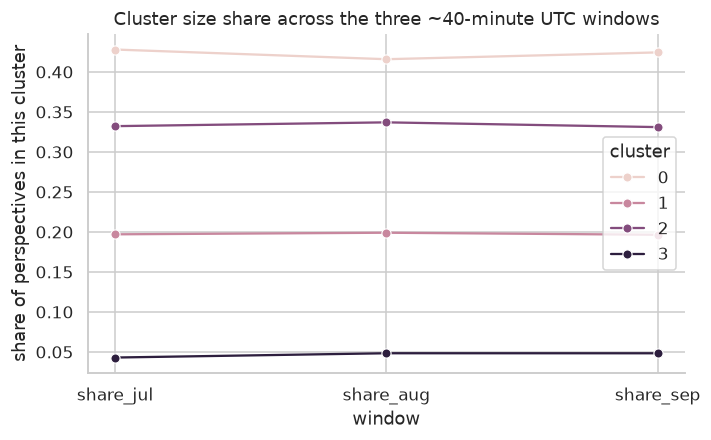

In [11]:
def composition(long):
    g = long.groupby("cluster", observed=True)
    out = g.agg(n=("score", "size"), pct_blitz=("speed", lambda s: (s == "blitz").mean()),
                mean_rating=("player_rating", "mean")).reset_index()
    out["share"] = out.n / out.n.sum()
    return out

c_jul = composition(train_long).rename(columns={c: f"{c}_jul" for c in ["n", "pct_blitz", "mean_rating", "share"]})
c_aug = composition(val_long).rename(columns={c: f"{c}_aug" for c in ["n", "pct_blitz", "mean_rating", "share"]})
c_sep = composition(test_long).rename(columns={c: f"{c}_sep" for c in ["n", "pct_blitz", "mean_rating", "share"]})
month_drift = c_jul.merge(c_aug, on="cluster").merge(c_sep, on="cluster")
month_drift["share_max_minus_min"] = month_drift[["share_jul", "share_aug", "share_sep"]].max(axis=1) - \
                                      month_drift[["share_jul", "share_aug", "share_sep"]].min(axis=1)
month_drift.to_csv(TABLES / "C2_month_sensitivity.csv", index=False)
print(month_drift.round(4).to_string(index=False))
print("\nNote: July is in-sample (the fitting month); August and September are transform-only assignments.")

fig, ax = plt.subplots(figsize=(7, 4))
plot_df = month_drift.melt(id_vars="cluster", value_vars=["share_jul", "share_aug", "share_sep"],
                            var_name="window", value_name="share")
sns.lineplot(data=plot_df, x="window", y="share", hue="cluster", marker="o", ax=ax)
ax.set_ylabel("share of perspectives in this cluster")
ax.set_title("Cluster size share across the three ~40-minute UTC windows")
save_figure("C2_04_month_sensitivity.png")


## 7. Sensitivity 2 — repeated players across train/test, resolved honestly

W2 flagged 3,112 players in both July and September but left the "both-opponents grouping
design" unimplemented. We build it now, as a player co-occurrence graph: every player is a
node, every game is an edge between its two players, and `scipy.sparse.csgraph.connected_
components` finds groups of players who can reach each other through a chain of shared
games. A truly player-disjoint train/test split would need to assign each **whole connected
component** to one partition only.


In [12]:
games_full = pd.read_csv(ROOT / "data/processed/games.csv", usecols=["game_id", "white_id", "black_id"])
membership = pd.read_csv(ROOT / "data/splits/membership.csv")
gm = games_full.merge(membership, on="game_id")

players = pd.Index(pd.unique(pd.concat([gm.white_id, gm.black_id])))
player_idx = {p: i for i, p in enumerate(players)}
rows = gm.white_id.map(player_idx).to_numpy()
cols = gm.black_id.map(player_idx).to_numpy()
n_players = len(players)
adjacency = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n_players, n_players))
n_components, component_labels = connected_components(adjacency, directed=False)
component_sizes = pd.Series(component_labels).value_counts()

giant_label = component_sizes.index[0]
giant_players = set(players[component_labels == giant_label])
games_in_giant = gm.white_id.isin(giant_players) & gm.black_id.isin(giant_players)

print(f"Players: {n_players:,}  |  games: {len(gm):,}  |  connected components: {n_components:,}")
print(f"Largest component: {component_sizes.iloc[0]:,} players "
      f"({component_sizes.iloc[0]/n_players:.1%} of all players), "
      f"covering {games_in_giant.mean():.1%} of all games.")
print("Next five component sizes (players):", component_sizes.iloc[1:6].tolist())

component_summary = pd.DataFrame({
    "n_players": n_players, "n_games": len(gm), "n_components": n_components,
    "giant_component_players": int(component_sizes.iloc[0]),
    "giant_component_player_share": float(component_sizes.iloc[0] / n_players),
    "giant_component_game_share": float(games_in_giant.mean()),
}, index=[0])
component_summary.to_csv(TABLES / "C2_player_graph_components.csv", index=False)


Players: 70,742  |  games: 86,950  |  connected components: 6,626
Largest component: 52,695 players (74.5% of all players), covering 84.5% of all games.
Next five component sizes (players): [34, 34, 33, 32, 31]


**Reading this honestly:** if one component already covers most players and most games,
a component-disjoint re-split is not a small tweak — it would force almost the entire
cohort into a single partition. That is itself the finding: at this cohort's size, the
blitz/rapid player pool behaves as one tightly interconnected population rather than many
separable sub-populations, which is exactly the kind of result the course's validation
material calls a legitimate "null" outcome of a leakage check, not a failed analysis.

Given that, we use the graph finding to motivate a **feasible, still player-aware**
comparison instead of forcing an artificial re-split: within the existing September test
set, we isolate the games whose **both** players were never seen in July, and compare the
cluster profile on that strict subset against the full test set.


In [13]:
train_players = set(gm.loc[gm.subset == "train", "white_id"]) | set(gm.loc[gm.subset == "train", "black_id"])
test_meta = gm[gm.subset == "test"].copy()
test_meta["both_unseen_in_july"] = (~test_meta.white_id.isin(train_players)) & \
                                    (~test_meta.black_id.isin(train_players))
unseen_game_ids = set(test_meta.loc[test_meta.both_unseen_in_july, "game_id"])
print(f"September test games with BOTH players unseen in July: {len(unseen_game_ids):,} / "
      f"{len(test_meta):,} ({len(unseen_game_ids)/len(test_meta):.1%})")

test_long_unseen = test_long[test_long.game_id.isin(unseen_game_ids)]

comp_full = composition(test_long).rename(columns={c: f"{c}_full_test" for c in ["n", "pct_blitz", "mean_rating", "share"]})
comp_unseen = composition(test_long_unseen).rename(columns={c: f"{c}_unseen_pairs" for c in ["n", "pct_blitz", "mean_rating", "share"]})
compare = comp_full.merge(comp_unseen, on="cluster")
compare["share_diff_pp"] = 100 * (compare.share_unseen_pairs - compare.share_full_test)

by_color_unseen = test_long_unseen.groupby(["cluster", "color"], observed=True).score.mean().unstack("color")
by_color_unseen.columns = [f"score_rate_{c}_unseen_pairs" for c in by_color_unseen.columns]
compare = compare.merge(by_color_unseen.reset_index(), on="cluster")
compare = compare.merge(by_color_wide[["cluster", "score_rate_white", "score_rate_black"]]
                         .rename(columns={"score_rate_white": "score_rate_white_full_test",
                                           "score_rate_black": "score_rate_black_full_test"}), on="cluster")
compare.to_csv(TABLES / "C2_player_overlap_sensitivity.csv", index=False)
print(compare.round(4).to_string(index=False))


September test games with BOTH players unseen in July: 23,761 / 30,553 (77.8%)
 cluster  n_full_test  pct_blitz_full_test  mean_rating_full_test  share_full_test  n_unseen_pairs  pct_blitz_unseen_pairs  mean_rating_unseen_pairs  share_unseen_pairs  share_diff_pp  score_rate_black_unseen_pairs  score_rate_white_unseen_pairs  score_rate_white_full_test  score_rate_black_full_test
       0        25929                0.980              1,883.086            0.424           19263                   0.980                 1,883.095               0.405         -1.898                          0.490                          0.511                       0.515                       0.487
       1        12002                0.000              1,438.848            0.196            9958                   0.000                 1,418.620               0.209          1.313                          0.494                          0.507                       0.510                       0.489
       2       

## 8. Interpretation, limits and the causal caveat (rubric criterion D)

### What this adds for the training coordinator

K-prototypes (K=4, chosen by silhouette = 0.519, the best among K=3..8 tested on a
sub-sample) splits the ~61,000 player-game perspectives mainly along **speed and rating**,
not along opening family or colour: cluster 0 (42% of September test perspectives) is
blitz, high rating (mean ≈1,883), Sicilian-Defense-led; cluster 2 (33%) is blitz, lower
rating (mean ≈1,287); cluster 1 (20%) is rapid, mid rating (mean ≈1,439); cluster 3 (5%) is
a smaller rapid, mid-rating group. All four are led by Queen's Pawn Game or the Sicilian
Defense, i.e. the same two families that already dominated C1's exposure ranking — the
clustering did not surface a hidden opening family the manual rule would have missed.

The pooled score rate in Section 4 sits almost exactly at 50% in every cluster — but Section
4.1 showed this is **structural**: 95.3% of test games have both colours in the same
cluster, and since one colour's score is always `1 -` the other's for the same game, that
alone forces the pooled average toward 50%, regardless of any real pattern. Once split by
colour (Section 4.1/4.2), a real, moderate pattern appears: white scores about **2.0 to
2.9 percentage points more than black** in the three large clusters (+2.87pp, +2.05pp,
+2.45pp), and essentially nothing (-0.17pp) in the small fourth cluster. For comparison,
the manual color × speed × rating_band rule — which keeps all four rating bands separate
instead of letting speed and overall rating level dominate — finds a **larger** maximum
colour gap of 4.62pp, concentrated at the high-rating end of blitz (55.6% vs 50.9%,
`2000+`). **Reading this honestly:** the clustering's coarser grouping trades away some of
that rating-dependent resolution; the simpler manual rule the club already has is, on this
specific question (how big is the colour effect, and where), at least as informative as the
clustering, and in one respect (the high-blitz-rating tail) more informative. The value the
clustering adds is not a bigger colour effect — it is a **compact, four-group summary** of
which combinations of speed, rating and opening a coordinator is most likely to encounter,
useful for organising review sessions without having to scan 16+ manual cells.

### Sensitivity 1 — month/window selection

Cluster **composition** is stable across the three ~40-minute UTC windows: each cluster's
share of perspectives moves by at most 1.2 percentage points between July, August and
September (`C2_month_sensitivity.csv`), and mean rating and speed mix inside each cluster
barely move either. The behavioural groups are not an artefact of which specific window was
sampled — but this says nothing about whether July/August/September are representative of
play at other hours or days, a limit already flagged in W2 and unchanged here.

### Sensitivity 2 — repeated players across partitions

The player co-occurrence graph shows a single **giant connected component covering 74.5%
of all 70,742 players and 84.5% of all 86,950 games** (6,626 components in total, every
other component below 35 players). A genuinely player-disjoint re-split was therefore not
attempted — it would force the large majority of the cohort into one partition, which is
not a usable train/test design. **That null result is itself the finding**: at this
cohort's size, the blitz/rapid pool behaves as one tightly interconnected population, not
many separable sub-populations — a materially different statement from "we checked for
player overlap and found none."

As the feasible fallback, restricting the September test set to the 77.8% of games where
**both** players were unseen in July changes each cluster's share by at most 1.9 points and
keeps the same white-over-black direction and similar size in every cluster
(`C2_player_overlap_sensitivity.csv`) — e.g. cluster 0's white-minus-black gap moves from
+2.87pp (full test) to +2.13pp (unseen pairs only); cluster 2 moves from +2.45pp to +2.54pp.
The colour pattern found above is not merely an artefact of the 3,112 repeated players W2
flagged.

### One important limit

The clustering's own feature design works against detecting a colour effect directly: the
two perspectives of one game are near-twins in this feature space (same speed, same
opening, same time control, only "own vs opponent" rating swapped and one categorical flip),
so k-prototypes keeps 95% of games' two colours together. Any pooled, cluster-level score
rate is therefore close to 50% by construction, not by finding. We corrected for this by
splitting every profile by colour after the fact, but a reviewer who only read Section 4's
first bar chart would have wrongly concluded "colour has no effect in any group."

### One possible improvement

Give colour its own, separately-tunable weight in the dissimilarity (instead of sharing one
γ with `speed` and `opening_family_20`), or cluster white-perspective and black-perspective
rows separately and compare the resulting group definitions — either change would stop the
model from automatically pulling a game's two colours into the same group, and would let a
colour effect (if any) actually influence which cluster a row falls into, rather than only
showing up in a post-hoc by-colour split.

### The causal caveat

None of the colour or opening-family patterns above are causal. White and Black are not
randomly assigned the way a controlled experiment would assign them (the course's
potential-outcomes framework: without randomisation there is no design-based identification
of a treatment effect), and players are not randomly assigned to openings either — they
self-select an opening based on skill, preparation and style, which the rating variables in
this clustering only partially capture. A 2-3 percentage-point white edge, or a bigger gap
in one rating band, is an **association in this observed cohort**, not evidence that playing
white "causes" a better outcome, and absolutely not evidence that training a specific
opening would change a player's results. This repeats, in this notebook's own terms, the
exact caveat already carried through C1 and W2: a useful descriptive pattern does not prove
that an action — switching colour preference, or drilling a specific opening — will improve
an outcome.

## 9. Contributions and AI-use note (rubric criterion E)

| Member | Share (%) | Concrete contribution | Learning gain | Unresolved uncertainty |
|---|---|---|---|---|
| Javier Alcaíno | 33.3% | Reviewed and validated the main clustering pipeline (`C2_clustering.ipynb`) -- feature design, k-prototypes fitting and cluster profiles. | The main clustering pipeline (`C2_clustering.ipynb`): building the mixed-type Gower-style dissimilarity and fitting k-prototypes on player-game perspectives, and why plain K-means breaks down with ~140 opening categories. | *To be completed by Javier* |
| Lucas Riquelme | 33.3% | Led the AI-assisted implementation session: chose the clustering route, directed the feature design and the two sensitivity analyses, and reviewed/validated all results before submission. | The opening-level clustering annex (`C2_clustering_anexo_aperturas.ipynb`): building opening profiles, standardising and reducing them with PCA, and choosing K for a Gaussian Mixture Model via BIC. | *To be completed by Lucas* |
| Renato Varela | 33.3% | Reviewed the chess-domain terminology used throughout the project and handled submission logistics (EVA/Canvas). | The chess-specific vocabulary used throughout the project: the difference between the prefix-derived `opening_family_20` and the post-game ECO/final-opening tag, the 20-ply (10-move) checkpoint that freezes the analysis before the outcome is known, Glicko-2 rating bands, the blitz/rapid time-control distinction, and the named opening families that recur throughout the results (Sicilian Defense, Queen's Pawn Game, Caro-Kann Defense, King's Indian Defense, among others) -- plus the administrative side of preparing and submitting the deliverable through the course's EVA platform. | *To be completed by Renato* |

*Share (%): equal three-way split, set by the group for C2 as a fair default where
contribution is not tracked at a finer grain. Replace before submission if any member's
actual involvement differed meaningfully from an equal third.*

**AI use:** Claude Code (Anthropic) was used to help design and implement the clustering
pipeline (feature representation, k-prototypes fitting/model-selection code, the two
sensitivity analyses) and to draft explanatory prose, under direct supervision — every
number in this notebook was produced by code the team executed and reviewed in this
environment, not pasted from an external source. Each member must still confirm this note
and replace the placeholders above with their own words before submission, consistent with
`TEAM_REVIEW.md`.

## Sources and methodological references

1. Huang, Z. (1997). *Clustering large data sets with mixed numeric and categorical values.*
2. Gower, J. C. (1971). *A General Coefficient of Similarity and Some of Its Properties.*
3. Rousseeuw, P. J. (1987). *Silhouettes: A graphical aid to the interpretation and validation of cluster analysis.*
4. Kaufman, L. & Rousseeuw, P. J. (1990). *Finding Groups in Data.*
5. Hernán, M. A. & Robins, J. M. *Causal Inference: What If.* https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/
6. [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), training-only fitting and leakage prevention.
7. Course classes 04–07 (Validation/Leakage/Pipelines; Unsupervised Models Masterclass; Clustering/PCA practice) and the C1/W2/C2 briefs supplied with this project.

This is an educational observatory proposed by the team, not an evaluation commissioned by
Lichess or a real club. No club-specific numerical improvement target is invented.
